<div align="center">

<!-- Judul Laporan -->
<h1><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h1>
</ul>
<!-- Logo Universitas -->
<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<div align="center">

<!-- Penulis -->
<h3>Disusun Oleh:</h3>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li style="display:flex; justify-content:space-between;"><span>ANANTA SAPUTRA</span><span>(H061241010)</span></li>
</ul>
<br><br>
<!-- Departemen dan Fakultas -->
<p><strong>PRODI GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong>UNIVERSITAS HASANUDDIN</strong></p>
<p><strong>MAKASSAR</strong></p>

<!-- Tahun -->
<p><strong>2026</strong></p>

</div>

## **Analisis Hasil Visualisasi Time-Series (R-VIS-001)**

In [1]:

from pathlib import Path
from datetime import datetime
import json
import sys

# ============================================================
# TUGAS KECERDASAN AI - CHAPTER 4
# Praktik Recipe buku + pembuatan Recipe sendiri
# ============================================================

# 1. PENGATURAN FOLDER
OUTPUT_DIR = Path(
    r"D:\KULIAH\Semester 5\Tugas Kecerdasan AI\Tugas_Recipe_Chapter4"
)

# GANTI JIKA LOKASI SHAPEFILE BERBEDA
INPUT_SHP = Path(
    r"D:\KULIAH\Semester 5\Analisis Geospasial\Ekspor Tugas 4"
    r"\Hasil Ekstrak\Bangunan\Bangunan_Gabungan_FINAL.shp"
)

IDEA = (
    "Memeriksa kualitas shapefile poligon bangunan "
    "sebelum digunakan dalam analisis geospasial."
)

RECIPE_BUKU = "R-META-001"
RECIPE_SENDIRI = "R-GIS-001"


# ============================================================
# 2. FUNGSI PENYIMPANAN
# ============================================================
def save_text(path, content):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(content.strip() + "\n", encoding="utf-8")


def save_json(path, data):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(
        json.dumps(data, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )


# ============================================================
# 3. PRAKTIK RECIPE DARI BUKU: R-META-001
# Mengubah gagasan menjadi scientific task
# ============================================================
def praktik_recipe_buku():
    task = {
        "recipe_id": RECIPE_BUKU,
        "judul": "Mengubah Gagasan Menjadi Scientific Task",
        "gagasan_awal": IDEA,
        "objective": (
            "Menilai kondisi dasar shapefile poligon bangunan "
            "sebelum digunakan untuk analisis geospasial."
        ),
        "inputs": [
            "Shapefile (.shp) dan file pendukungnya",
            "Informasi CRS yang diharapkan jika diketahui",
            "Kriteria atribut jika diperlukan"
        ],
        "scope": (
            "Satu shapefile poligon bangunan. "
            "Tidak melakukan analisis temporal."
        ),
        "assumptions": [
            "File yang dipilih merupakan layer bangunan",
            "CRS perlu dikonfirmasi dengan sumber data",
            "Poligon berdekatan tidak otomatis merupakan duplikat"
        ],
        "expected_outputs": [
            "Laporan audit Markdown",
            "Ringkasan CRS, jumlah fitur, dan kolom",
            "Pemeriksaan geometri kosong dan tidak valid"
        ],
        "constraints": [
            "File asli tidak boleh diubah",
            "Tidak menghapus fitur secara otomatis",
            "Tidak memperbaiki geometri secara otomatis",
            "Tidak mengarang hasil pemeriksaan"
        ]
    }

    prompt = f"""
# P-META-001 — Clarify a Scientific Task

Gagasan awal:
{IDEA}

Ubah gagasan tersebut menjadi scientific task yang jelas.

Jelaskan:
1. Objective atau tujuan.
2. Required inputs atau data yang diperlukan.
3. Scope atau ruang lingkup.
4. Assumptions atau asumsi.
5. Expected outputs atau keluaran.
6. Constraints atau batasan.

Jangan mengarang informasi tentang data yang belum diperiksa.
"""

    save_json(
        OUTPUT_DIR / "results" / "task_specification.json",
        task
    )

    save_text(
        OUTPUT_DIR / "prompts" / "P-META-001.md",
        prompt
    )

    laporan = f"""
# Praktik Recipe dari Buku: {RECIPE_BUKU}

## Judul
Mengubah Gagasan Menjadi Scientific Task

## Gagasan Awal
{IDEA}

## Objective
{task["objective"]}

## Input
""" + "\n".join(f"- {x}" for x in task["inputs"]) + """

## Scope
""" + task["scope"] + """

## Assumptions
""" + "\n".join(f"- {x}" for x in task["assumptions"]) + """

## Expected Outputs
""" + "\n".join(f"- {x}" for x in task["expected_outputs"]) + """

## Constraints
""" + "\n".join(f"- {x}" for x in task["constraints"]) + """

## Kesimpulan
Gagasan awal yang masih umum telah diubah menjadi scientific task
dengan tujuan, input, ruang lingkup, asumsi, keluaran, dan batasan
yang dapat diperiksa.

Dokumen ini merupakan hasil penyusunan spesifikasi task. Dokumen ini
tidak berarti bahwa shapefile telah diperiksa.
"""

    save_text(
        OUTPUT_DIR / "results" / "praktik_R-META-001.md",
        laporan
    )

    print("[OK] Praktik R-META-001 selesai.")


# ============================================================
# 4. RECIPE BUATAN SENDIRI: R-GIS-001
# ============================================================
def buat_recipe_sendiri():
    recipe = """
# R-GIS-001 — Audit Kualitas Shapefile Bangunan

## Problem
Shapefile bangunan perlu diperiksa sebelum digunakan dalam
analisis geospasial agar struktur data dan kondisi geometrinya
dapat diketahui.

## Minimal Theory
Shapefile menyimpan geometri dan atribut. Audit dasar dapat
memeriksa CRS, jumlah fitur, kolom atribut, geometri kosong,
dan geometri tidak valid. Geometri berdekatan tidak otomatis
berarti duplikat.

## AI Role
Asisten analisis geospasial yang membantu menyusun dan meninjau
audit data menggunakan Python dan GeoPandas.

## Recommended Stack
- Python
- GeoPandas
- Pandas
- JSON dan Markdown

## Prompt ID
P-GIS-001

## Ready-to-use Prompt
Bertindak sebagai asisten analisis geospasial. Periksa shapefile
poligon bangunan berdasarkan CRS, jumlah fitur, kolom atribut,
geometri kosong, dan geometri tidak valid. Laporkan hasil
berdasarkan data yang benar-benar dibaca. Jangan mengubah file
asli, menghapus fitur, atau memperbaiki geometri otomatis.
Jangan menyatakan poligon berdekatan sebagai duplikat tanpa
pemeriksaan lebih lanjut. Jika file gagal dibaca atau CRS tidak
tersedia, jelaskan keterbatasannya.

## Code Outline
1. Memeriksa keberadaan file input.
2. Membaca shapefile menggunakan GeoPandas.
3. Memeriksa CRS dan jumlah fitur.
4. Memeriksa kolom atribut dan tipe geometri.
5. Menghitung geometri kosong dan tidak valid.
6. Menyimpan laporan audit terpisah.

## Expected Output
- results/audit_shapefile.json
- results/audit_shapefile.md
- results/run_record_R-GIS-001.json

## Optional Check
Buka layer di QGIS dan cocokkan CRS, jumlah fitur, serta
kolom atribut dengan laporan.

## Reproducibility Note
Catat path input, waktu eksekusi, versi Python dan GeoPandas,
jumlah fitur, status, serta pesan kesalahan.

## Related Recipe
R-META-001 — Mengubah Gagasan Menjadi Scientific Task.
"""

    prompt = """
# P-GIS-001 — Audit Kualitas Shapefile Bangunan

Bertindak sebagai asisten analisis geospasial. Periksa shapefile
poligon bangunan berdasarkan CRS, jumlah fitur, kolom atribut,
geometri kosong, dan geometri tidak valid. Laporkan hasil
berdasarkan data yang benar-benar dibaca. Jangan mengubah file
asli, menghapus fitur, atau memperbaiki geometri otomatis.
Jika file gagal dibaca atau CRS tidak tersedia, jelaskan
keterbatasannya.
"""

    save_text(
        OUTPUT_DIR / "recipes" / "R-GIS-001.md",
        recipe
    )
    save_text(
        OUTPUT_DIR / "prompts" / "P-GIS-001.md",
        prompt
    )

    print("[OK] Recipe R-GIS-001 berhasil dibuat.")


# ============================================================
# 5. AUDIT SHAPEFILE
# ============================================================
def audit_shapefile():
    record = {
        "recipe_id": RECIPE_SENDIRI,
        "input_path": str(INPUT_SHP),
        "started_at": datetime.now().isoformat(timespec="seconds"),
        "status": "not_executed",
        "checks": [],
        "error": None
    }

    # Jika path salah, jangan mengarang hasil
    if not INPUT_SHP.exists():
        record["status"] = "input_not_found"
        record["error"] = (
            "File tidak ditemukan. Sesuaikan variabel INPUT_SHP."
        )

        save_text(
            OUTPUT_DIR / "results" / "audit_shapefile.md",
            f"""
# Audit Shapefile

Status: BELUM DIJALANKAN

File tidak ditemukan:
`{INPUT_SHP}`

Silakan sesuaikan INPUT_SHP dengan path shapefile yang benar,
kemudian jalankan script kembali.
"""
        )

        save_json(
            OUTPUT_DIR / "results" / "run_record_R-GIS-001.json",
            record
        )

        print("[PERINGATAN] Shapefile tidak ditemukan.")
        print("Ubah INPUT_SHP di bagian pengaturan.")
        return

    try:
        import geopandas as gpd
        import pandas as pd

        # Membaca data tanpa mengubah file sumber
        gdf = gpd.read_file(INPUT_SHP)

        geom = gdf.geometry

        null_count = int(geom.isna().sum())
        empty_count = int(geom.is_empty.fillna(False).sum())
        invalid_count = int((~geom.is_valid).fillna(False).sum())

        geometry_types = {
            str(k): int(v)
            for k, v in geom.geom_type.value_counts(
                dropna=False
            ).items()
        }

        report = {
            "recipe_id": RECIPE_SENDIRI,
            "input_path": str(INPUT_SHP),
            "checked_at": datetime.now().isoformat(
                timespec="seconds"
            ),
            "crs": str(gdf.crs) if gdf.crs else None,
            "feature_count": int(len(gdf)),
            "columns": [str(c) for c in gdf.columns],
            "geometry_types": geometry_types,
            "null_geometry_count": null_count,
            "empty_geometry_count": empty_count,
            "invalid_geometry_count": invalid_count,
            "source_modified": False,
            "limitations": [
                "File asli tidak diubah",
                "Geometri tidak diperbaiki otomatis",
                "Audit dasar tidak menggantikan pemeriksaan topologi",
                "CRS harus dikonfirmasi terhadap sumber data"
            ]
        }

        save_json(
            OUTPUT_DIR / "results" / "audit_shapefile.json",
            report
        )

        columns = "\n".join(
            f"- `{c}`" for c in report["columns"]
        )

        types = "\n".join(
            f"- {k}: {v}"
            for k, v in geometry_types.items()
        ) or "- Tidak ada tipe geometri yang terbaca."

        if gdf.crs is None:
            crs_note = (
                "CRS tidak tersedia. Konfirmasi CRS dari sumber data."
            )
        else:
            crs_note = (
                f"CRS tercatat sebagai `{gdf.crs}`. "
                "Pastikan CRS sesuai dengan sumber data."
            )

        laporan = f"""
# Laporan Audit Shapefile Bangunan

## Identitas
- Recipe: {RECIPE_SENDIRI}
- File: `{INPUT_SHP}`
- Waktu pemeriksaan: {report["checked_at"]}
- File sumber diubah: Tidak

## Ringkasan
- CRS: {report["crs"] or "Tidak tersedia"}
- Jumlah fitur: {len(gdf)}
- Geometri null: {null_count}
- Geometri kosong: {empty_count}
- Geometri tidak valid: {invalid_count}

## Kolom Atribut
{columns}

## Tipe Geometri
{types}

## Interpretasi Awal
- {crs_note}
- Jumlah fitur yang terbaca: {len(gdf)}.
- Geometri kosong dan tidak valid perlu ditinjau sebelum
  digunakan dalam analisis lanjutan.

## Keterbatasan
- Audit ini tidak memperbaiki atau menghapus fitur.
- Geometri valid belum tentu benar secara geografis.
- Pemeriksaan visual di QGIS tetap disarankan.
"""

        save_text(
            OUTPUT_DIR / "results" / "audit_shapefile.md",
            laporan
        )

        record["status"] = "executed_locally"
        record["checks"] = [
            "shapefile_readable",
            "crs_checked",
            "feature_count_checked",
            "columns_checked",
            "geometry_types_checked",
            "null_empty_invalid_geometry_checked"
        ]
        record["feature_count"] = int(len(gdf))
        record["crs"] = str(gdf.crs) if gdf.crs else None
        record["versions"] = {
            "python": sys.version.split()[0],
            "geopandas": gpd.__version__,
            "pandas": pd.__version__
        }

        print("[OK] Audit shapefile berhasil dijalankan.")

    except ImportError as exc:
        record["status"] = "dependency_missing"
        record["error"] = str(exc)

        save_text(
            OUTPUT_DIR / "results" / "audit_shapefile.md",
            """
# Audit Shapefile — Dependency Belum Tersedia

GeoPandas atau Pandas belum tersedia pada Python yang digunakan.

Jalankan perintah berikut di terminal VS Code:
python -m pip install geopandas

Pastikan interpreter Python yang dipilih VS Code sesuai dengan
environment tempat GeoPandas dipasang, lalu jalankan kembali.
"""
        )

        print("[ERROR] GeoPandas/Pandas belum tersedia.")

    except Exception as exc:
        record["status"] = "failed"
        record["error"] = f"{type(exc).__name__}: {exc}"

        save_text(
            OUTPUT_DIR / "results" / "audit_shapefile.md",
            f"""
# Audit Shapefile — Gagal

File input: `{INPUT_SHP}`

Jenis kesalahan:
`{type(exc).__name__}: {exc}`

Periksa path, kelengkapan file .shp, .shx, .dbf, dan .prj,
serta pastikan file tidak sedang bermasalah atau terkunci.
"""
        )

        print("[ERROR] Audit gagal:", record["error"])

    record["finished_at"] = datetime.now().isoformat(
        timespec="seconds"
    )

    save_json(
        OUTPUT_DIR / "results" / "run_record_R-GIS-001.json",
        record
    )

    print("Status audit:", record["status"])


# ============================================================
# 6. PROGRAM UTAMA
# ============================================================
def main():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    print("=" * 60)
    print("TUGAS KECERDASAN AI — CHAPTER 4")
    print("=" * 60)

    praktik_recipe_buku()
    buat_recipe_sendiri()
    audit_shapefile()

    print("\nProses selesai.")
    print("Folder hasil:", OUTPUT_DIR)
    print("\nPeriksa folder results, prompts, dan recipes.")
    print(
        "Jangan menyatakan audit berhasil jika statusnya "
        "bukan executed_locally."
    )


if __name__ == "__main__":
    main()


TUGAS KECERDASAN AI — CHAPTER 4
[OK] Praktik R-META-001 selesai.
[OK] Recipe R-GIS-001 berhasil dibuat.
[OK] Audit shapefile berhasil dijalankan.
Status audit: executed_locally

Proses selesai.
Folder hasil: D:\KULIAH\Semester 5\Tugas Kecerdasan AI\Tugas_Recipe_Chapter4

Periksa folder results, prompts, dan recipes.
Jangan menyatakan audit berhasil jika statusnya bukan executed_locally.


PRAKTIK RECIPE R-VIS-001
TIME-SERIES FIGURE UNTUK DATA GEOFISIKA
Jumlah sampel       : 5000
Interval sampling   : 0.002 s
Durasi pengamatan   : 10.0 s
Waktu impuls        : 3.0 s
Frekuensi gelombang : 5.0 Hz
Amplitudo maksimum  : 1.263
Amplitudo minimum   : -1.267


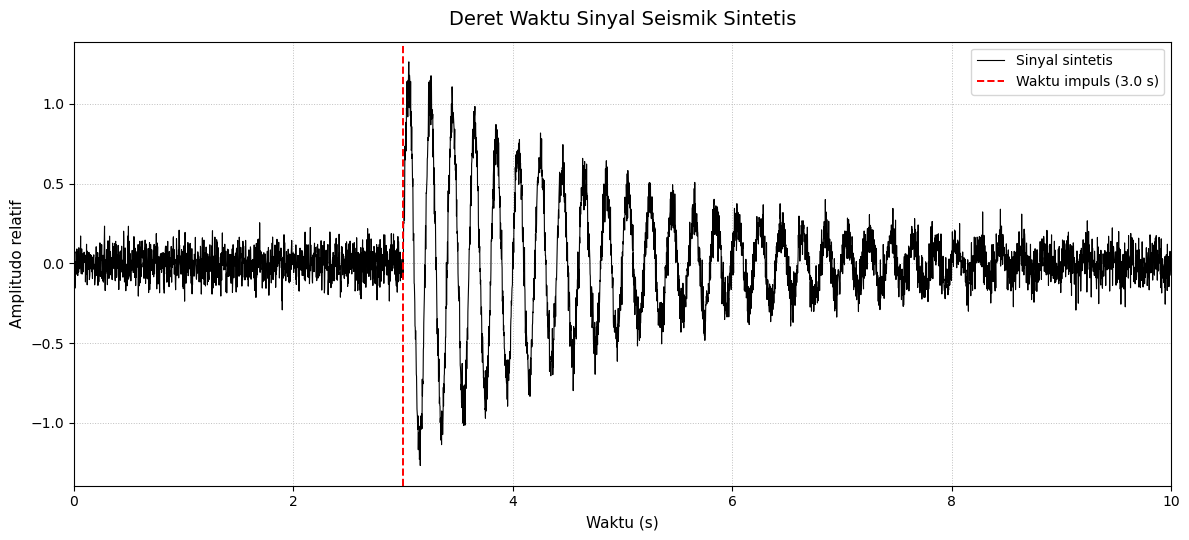


Grafik berhasil dibuat.
Lokasi hasil grafik: D:\KULIAH\Semester 5\Kecerdasan Artifisial\hasil_R_VIS_001\time_series_sinyal_sintetis.png

HASIL DAN PEMBAHASAN

Grafik memperlihatkan perubahan amplitudo sinyal seismik
sintetis terhadap waktu selama 10 detik.

Sebelum 3 detik, sinyal didominasi oleh noise dengan
amplitudo relatif kecil. Pada waktu 3 detik, gelombang
sintetis mulai muncul dan amplitudonya berangsur menurun
akibat faktor redaman yang diterapkan pada model.

Garis vertikal putus-putus menunjukkan waktu impuls.
Label sumbu, legenda, dan grid membantu pembaca memahami
perubahan sinyal terhadap waktu.

Grafik disimpan dalam format PNG dengan resolusi 300 dpi
agar dapat digunakan dalam laporan praktikum.

Data ini merupakan data sintetis, bukan rekaman gempa
bumi nyata.

KESIMPULAN

Praktik Recipe R-VIS-001 menerapkan visualisasi deret waktu
menggunakan Python, NumPy, dan Matplotlib.

Sinyal sintetis dapat ditampilkan terhadap waktu dengan
penanda impuls serta elemen grafik yan

In [2]:
# ============================================================
# TUGAS KECERDASAN ARTIFISIAL UNTUK GEOFISIKA
# RECIPE R-VIS-001
# MEMBUAT TIME-SERIES FIGURE YANG INFORMATIF
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# 1. PENGATURAN FOLDER DAN PARAMETER
# ============================================================

OUTPUT_DIR = Path("hasil_R_VIS_001")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Parameter waktu
dt = 0.002
durasi = 10.0
waktu = np.arange(0, durasi, dt)

# Parameter gelombang sintetis
t_kedatangan = 3.0
frekuensi = 5.0

# Seed agar hasil dapat direproduksi
rng = np.random.default_rng(42)

# ============================================================
# 2. MEMBANGUN DATA SINTETIS
# ============================================================

# Membuat noise acak
noise = 0.08 * rng.normal(size=len(waktu))

# Membuat gelombang seismik sintetis
waktu_rel = waktu - t_kedatangan
gelombang = np.zeros_like(waktu)

mask = waktu >= t_kedatangan

gelombang[mask] = (
    1.2
    * np.sin(2 * np.pi * frekuensi * waktu_rel[mask])
    * np.exp(-waktu_rel[mask] / 2.0)
)

# Menggabungkan noise dan gelombang
amplitudo = noise + gelombang

# ============================================================
# 3. MENAMPILKAN INFORMASI DATA
# ============================================================

print("=" * 55)
print("PRAKTIK RECIPE R-VIS-001")
print("TIME-SERIES FIGURE UNTUK DATA GEOFISIKA")
print("=" * 55)

print(f"Jumlah sampel       : {len(waktu)}")
print(f"Interval sampling   : {dt:.3f} s")
print(f"Durasi pengamatan   : {durasi:.1f} s")
print(f"Waktu impuls        : {t_kedatangan:.1f} s")
print(f"Frekuensi gelombang : {frekuensi:.1f} Hz")
print(f"Amplitudo maksimum  : {np.max(amplitudo):.3f}")
print(f"Amplitudo minimum   : {np.min(amplitudo):.3f}")

# ============================================================
# 4. MEMBUAT GRAFIK TIME SERIES
# ============================================================

fig, ax = plt.subplots(figsize=(12, 5.5))

# Plot sinyal sintetis
ax.plot(
    waktu,
    amplitudo,
    color="black",
    linewidth=0.8,
    label="Sinyal sintetis"
)

# Menandai waktu kedatangan impuls
ax.axvline(
    x=t_kedatangan,
    color="red",
    linestyle="--",
    linewidth=1.4,
    label=f"Waktu impuls ({t_kedatangan:.1f} s)"
)

# Judul dan label sumbu
ax.set_title(
    "Deret Waktu Sinyal Seismik Sintetis",
    fontsize=14,
    pad=12
)

ax.set_xlabel("Waktu (s)", fontsize=11)
ax.set_ylabel("Amplitudo relatif", fontsize=11)

# Pengaturan tampilan grafik
ax.set_xlim(0, durasi)
ax.grid(
    True,
    linestyle=":",
    linewidth=0.7,
    alpha=0.8
)

ax.legend(loc="upper right")
fig.tight_layout()

# ============================================================
# 5. MENYIMPAN GRAFIK
# ============================================================

file_gambar = OUTPUT_DIR / "time_series_sinyal_sintetis.png"

fig.savefig(
    file_gambar,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nGrafik berhasil dibuat.")
print(f"Lokasi hasil grafik: {file_gambar.resolve()}")

# ============================================================
# 6. ANALISIS HASIL
# ============================================================

print("\n" + "=" * 55)
print("HASIL DAN PEMBAHASAN")
print("=" * 55)

print("""
Grafik memperlihatkan perubahan amplitudo sinyal seismik
sintetis terhadap waktu selama 10 detik.

Sebelum 3 detik, sinyal didominasi oleh noise dengan
amplitudo relatif kecil. Pada waktu 3 detik, gelombang
sintetis mulai muncul dan amplitudonya berangsur menurun
akibat faktor redaman yang diterapkan pada model.

Garis vertikal putus-putus menunjukkan waktu impuls.
Label sumbu, legenda, dan grid membantu pembaca memahami
perubahan sinyal terhadap waktu.

Grafik disimpan dalam format PNG dengan resolusi 300 dpi
agar dapat digunakan dalam laporan praktikum.

Data ini merupakan data sintetis, bukan rekaman gempa
bumi nyata.
""")

# ============================================================
# 7. KESIMPULAN
# ============================================================

print("=" * 55)
print("KESIMPULAN")
print("=" * 55)

print("""
Praktik Recipe R-VIS-001 menerapkan visualisasi deret waktu
menggunakan Python, NumPy, dan Matplotlib.

Sinyal sintetis dapat ditampilkan terhadap waktu dengan
penanda impuls serta elemen grafik yang informatif.
Visualisasi ini membantu memahami perubahan amplitudo
dan waktu kemunculan gelombang pada data simulasi.
""")

# ============================================================
# 8. REFERENSI
# ============================================================

print("=" * 55)
print("REFERENSI")
print("=" * 55)

print("""
AI Cookbook untuk Earth Sciences.
Recipe R-VIS-001: Membuat Time-Series Figure
yang Informatif.

Catatan: Kode ini merupakan implementasi praktik
berdasarkan tujuan umum recipe, bukan salinan persis
kode sumber buku.
""")

print("Proses selesai.")
print(f"Folder hasil: {OUTPUT_DIR.resolve()}")

## Analisis Hasil Visualisasi Time-Series (R-VIS-001)

Visualisasi deret waktu (*time series*) dibuat untuk merepresentasikan perubahan amplitudo sinyal seismik sintetis terhadap waktu. Berdasarkan grafik yang dihasilkan, pada rentang waktu sebelum 3 detik, sinyal didominasi oleh noise acak dengan amplitudo relatif kecil. Ketika mencapai waktu 3 detik, gelombang sintetis mulai muncul dengan pola osilasi yang jelas, kemudian amplitudonya berangsur menurun akibat faktor redaman yang diterapkan dalam simulasi.

Kemunculan gelombang tersebut dapat diamati melalui garis vertikal putus-putus yang menandai waktu impuls pada 3 detik. Pola perubahan amplitudo setelah waktu tersebut memperlihatkan karakteristik gelombang yang mengalami pelemahan seiring bertambahnya waktu. Penggunaan label sumbu waktu dalam sekon, label amplitudo relatif, legenda, dan grid membantu memperjelas interpretasi grafik. Selain itu, penyimpanan gambar dalam format PNG dengan resolusi 300 dpi menghasilkan visualisasi yang dapat digunakan dalam laporan praktikum.

Hasil ini menunjukkan bahwa penerapan recipe R-VIS-001 dapat membantu menyajikan data geofisika berbasis deret waktu secara lebih informatif dan sistematis. Namun, karena data yang digunakan merupakan hasil simulasi sintetis, pola gelombang yang terlihat tidak dapat langsung digunakan untuk menyimpulkan karakteristik kejadian gempa bumi atau kondisi bawah permukaan yang sebenarnya.